# 1. Set up the notebook

Do imports.

In [242]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from IPython.display import Image
from ae483.tools import *
from ae483.mytools import *

# 2. Estimate the mass

Find the mass $m$ of the drone in kilograms.

In [243]:
m = 0.04 # <-- FIXME

Find a worst-case bound $\Delta m$ on the uncertainty of your estimate. This bound should be chosen so that the true mass is guaranteed to be in the interval $[m - \Delta m, m + \Delta m]$.

In [244]:
delta_m = 0.001 # <-- FIXME

# 3. Estimate the moment of inertia about the $x_B$-axis

Show a picture of your rig (change the file name or file extension as appropriate).

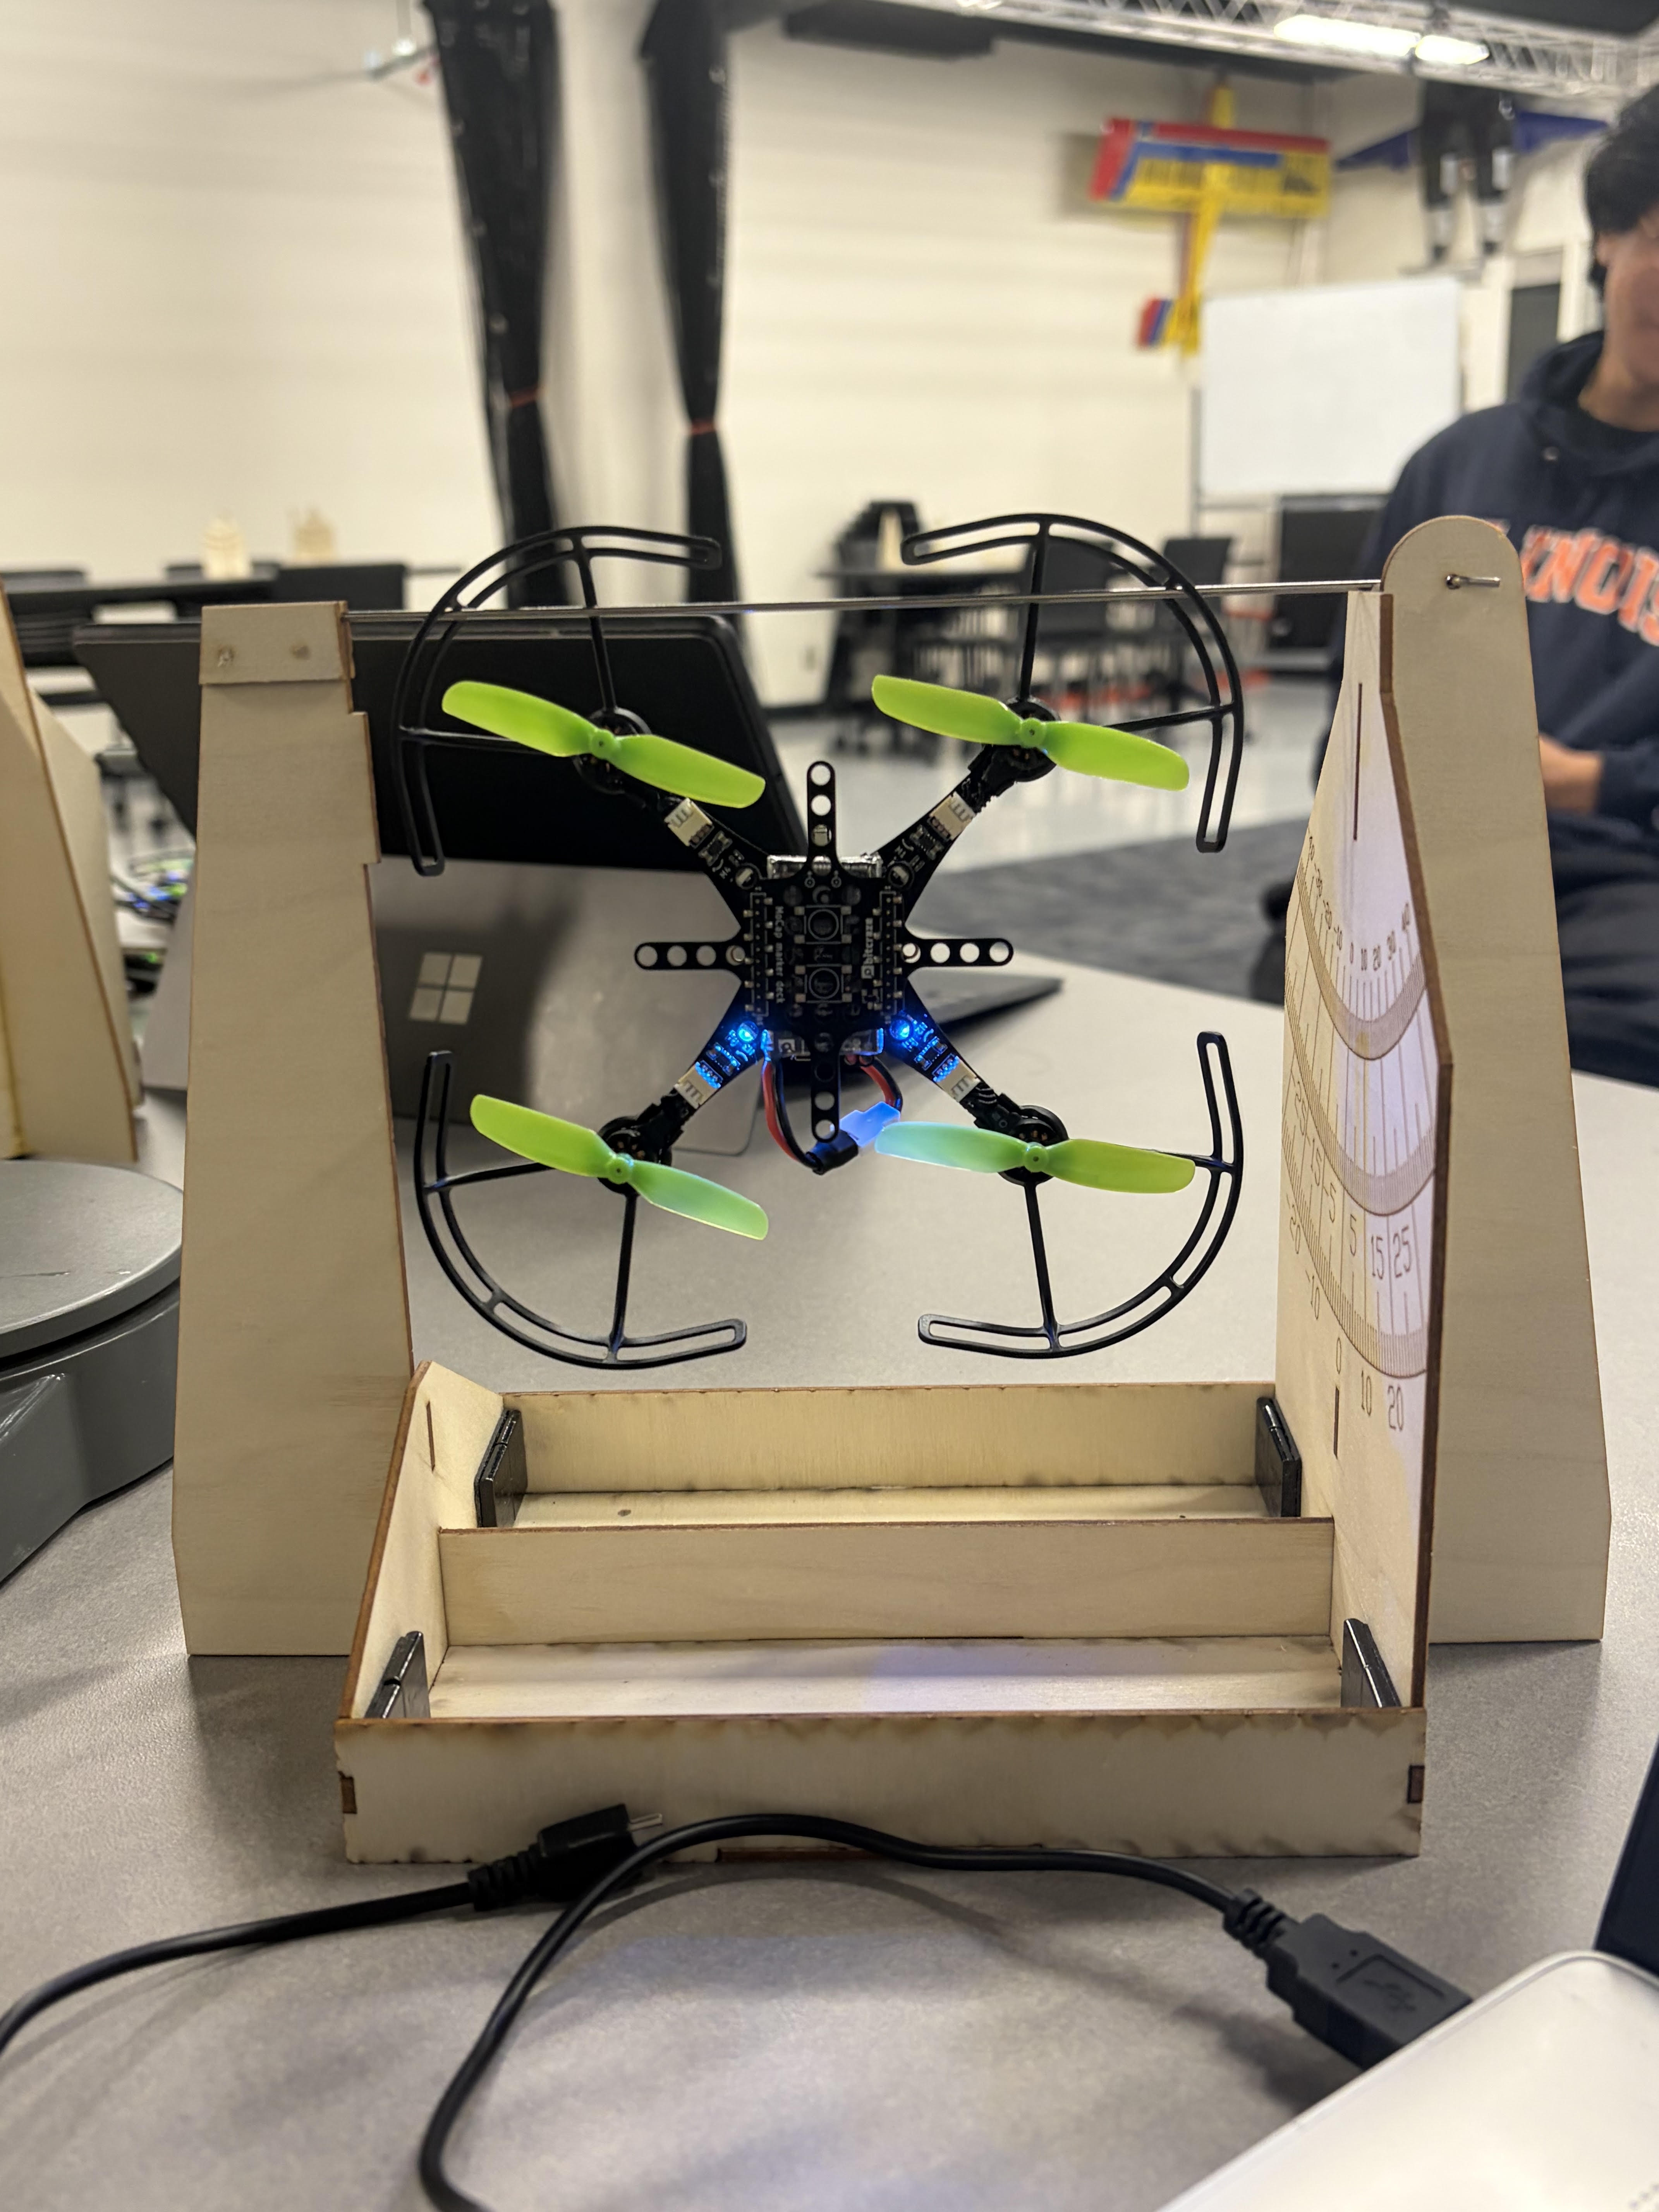

In [245]:
Image(filename='x-rig.png', width=480)

Find the distance in meters between the axis of rotation and the center of mass.

In [246]:
r = 0.06 # <-- FIXME

Find a worst-case bound $\Delta r$ on the uncertainty of your estimate.

In [247]:
delta_r = 0.001 # <-- FIXME

Load, resample, and parse data to get time and the three components of angular velocity (in radians / second).

Remember that `resample_drone_data` has two optional arguments that allow you to discard data at the start and end of the experiment. You may find these arguments useful, since you will likely find that some of the data at the start and end of your experiment are garbage.

In [248]:
# Load data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('x_data.json')

# Resample data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0.,    # <-- FIXME
    t_max_offset=0.,    # <-- FIXME
)

# Parse data
t = data_drone['time']
w_x = np.deg2rad(data_drone['gyro.x'])
w_y = np.deg2rad(data_drone['gyro.y'])
w_z = np.deg2rad(data_drone['gyro.z'])

Plot all three components of angular velocity. You are trying to estimate the moment of inertia about the $x$ axis. The component of angular velocity about this axis should be large, and the components of angular velocity about the other two axes should be negligibly small. It is important to check this. (Please also check if you have data at the start and end of the experiment that need to be discarded.)

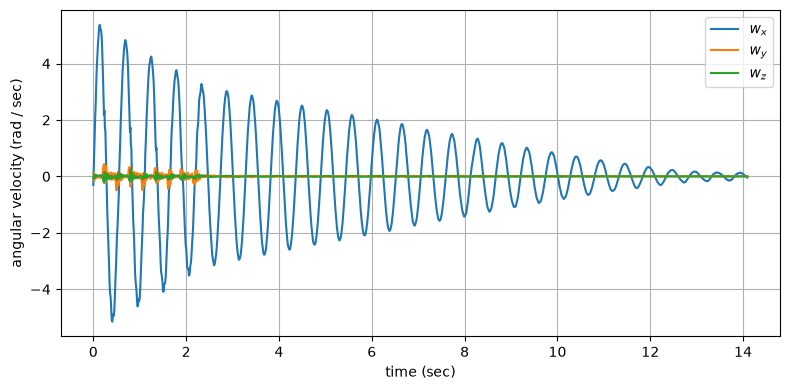

In [249]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4), tight_layout=True)
ax.plot(t, w_x, label='$w_x$')
ax.plot(t, w_y, label='$w_y$')
ax.plot(t, w_z, label='$w_z$')
ax.set_xlabel('time (sec)')
ax.set_ylabel('angular velocity (rad / sec)')
ax.legend()
ax.grid()
plt.show()

You should find that `w_x` is oscillatory. The period is the peak-to-peak time. You could measure the period by hand, but it is easier to automate this process, particularly if you want to average your estimate of the period over many oscillations.

Here is one way to do it:

* Find the index $i_k$ of each peak $k\in\{0, \dotsc, n-1\}$ in your data.
* Find the time $t_k$ at each peak for $k\in\{0, \dotsc, n-1\}$.
* Find the difference $T_k = t_{k+1} - t_k$ between consecutive peak times for $k \in \{0, \dotsc, n-2\}$.
* Find the mean difference: $$\widehat{T} = \dfrac{1}{n-1} \sum_{k=0}^{n-2} T_k.$$ This is an estimate of the oscillation period.

Here is one way to implement this in code, using [scipy.signal.find_peaks](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.find_peaks.html):

In [250]:
# Find the index of each peak (increase "prominence" if you get bad results)
peaks = find_peaks(w_x, prominence=1)
i_peaks = peaks[0]

# Find the time at each peak
t_peaks = t[i_peaks]

# Find w_x at each peak (for visualization)
w_x_peaks = w_x[i_peaks]

# Find the difference between consecutive peak times
#
# Note:
#
#  t_peaks[1:] means t_peaks without the first element
#  t_peaks[:-1] means t_peaks without the last element
#
# So, t_peaks[1:] - t_peaks[:-1] produces the following array:
#
#  [t_peaks[1]-t_peaks[0], t_peaks[0]-t_peaks[1], ...]
#
t_diff = t_peaks[1:] - t_peaks[:-1]

# Find the mean difference as an estimate of the oscillation period
T = np.mean(t_diff)

# Print the estimate
print(f'T = {T:.4f} sec')

T = 0.5390 sec


Sanity check — plot the peaks. (**FIXME: How do you know these results are good?**)

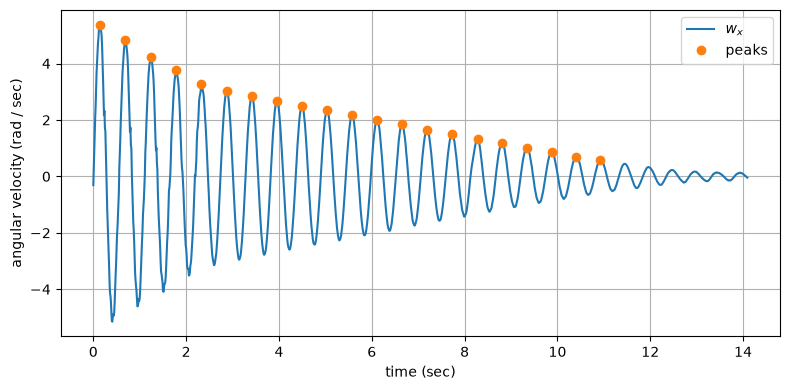

In [251]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4), tight_layout=True)
ax.plot(t, w_x, label='$w_x$')
ax.plot(t_peaks, w_x_peaks, '.', markersize=12, label='peaks')
ax.set_xlabel('time (sec)')
ax.set_ylabel('angular velocity (rad / sec)')
ax.legend()
ax.grid()
plt.show()

Sanity check — plot the differences between consecutive peak times. (**FIXME: How do you know these results are good?**)

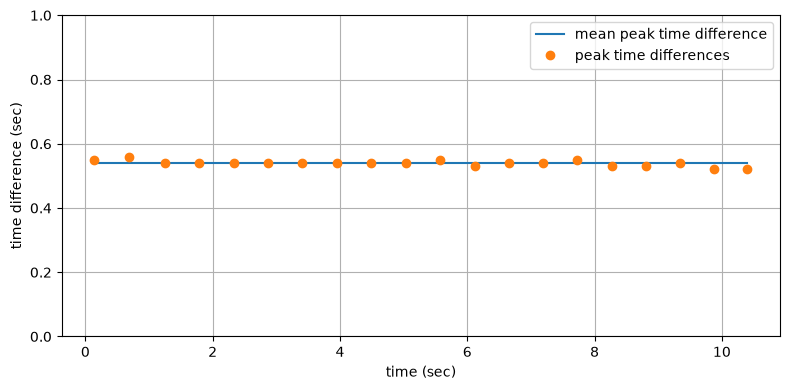

In [252]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4), tight_layout=True)
ax.plot(t_peaks[:-1], T * np.ones_like(t_peaks[:-1]), label='mean peak time difference')
ax.plot(t_peaks[:-1], t_diff, '.', markersize=12, label='peak time differences')
ax.set_ylim(0., 1.)
ax.set_xlabel('time (sec)')
ax.set_ylabel('time difference (sec)')
ax.grid()
ax.legend()
plt.show()

Find a worst-case bound $\Delta T$ on the uncertainty of your estimate.

In [253]:
delta_T = max(abs(t_diff - T * np.ones_like(t_peaks[:-1])))
print(delta_T)

0.02100000000000013


Find the moment of inertia about the $x$ axis.

In [254]:
g = 9.8065

J_x = m * (g * r * T**2 / (4 * np.pi**2) - r**2)
print(J_x)



2.919807789979148e-05


Find a worst-case bound $\Delta J_x$ on the uncertainty in your estimate.

In [255]:

delta_J_x = (
        abs(m * (g * T**2 / (4 * np.pi**2) - 2*r)) * delta_r
        + abs(g * r * T**2 / (4 * np.pi**2) - r**2) * delta_m
        + abs(m * g * r * T / (2 * np.pi**2)) * delta_T
    )
print(delta_J_x)

1.6139271437893354e-05


# 4. Estimate the moment of inertia about the $y_B$-axis

Reload the data using the appropriate data set.

In [256]:
# Load data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('y_data.json')

# Resample data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0.,    # <-- FIXME
    t_max_offset=0.,    # <-- FIXME
)

# Parse data
t = data_drone['time']
w_x = np.deg2rad(data_drone['gyro.x'])
w_y = np.deg2rad(data_drone['gyro.y'])
w_z = np.deg2rad(data_drone['gyro.z'])

Reinitialize 'r' with the proper distance from axis of rotation to center of mass. Then use the same procedure as above to determine the peaks and mean time difference.

In [257]:
r = 0.06
delta_r = 0.001

# Find the index of each peak (increase "prominence" if you get bad results)
peaks = find_peaks(w_y, prominence=1)
i_peaks = peaks[0]

# Find the time at each peak
t_peaks = t[i_peaks]

# Find w_x at each peak (for visualization)
w_y_peaks = w_y[i_peaks]

t_diff = t_peaks[1:] - t_peaks[:-1]

# Find the mean difference as an estimate of the oscillation period
T = np.mean(t_diff)

# Print the estimate
print(f'T = {T:.4f} sec')

T = 0.5432 sec


Check the determined peaks to ensure the data set has no off peak elements.

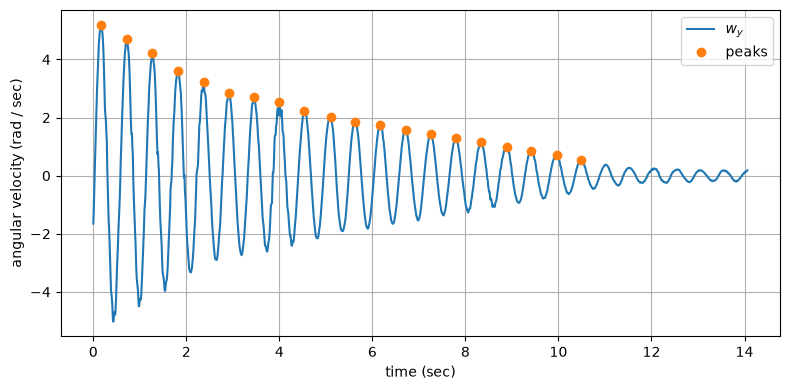

In [258]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4), tight_layout=True)
ax.plot(t, w_y, label='$w_y$')
ax.plot(t_peaks, w_y_peaks, '.', markersize=12, label='peaks')
ax.set_xlabel('time (sec)')
ax.set_ylabel('angular velocity (rad / sec)')
ax.legend()
ax.grid()
plt.show()

Plot and check the peak time differences against the mean peak time difference to ensure all data elements are near the mean as is expected.

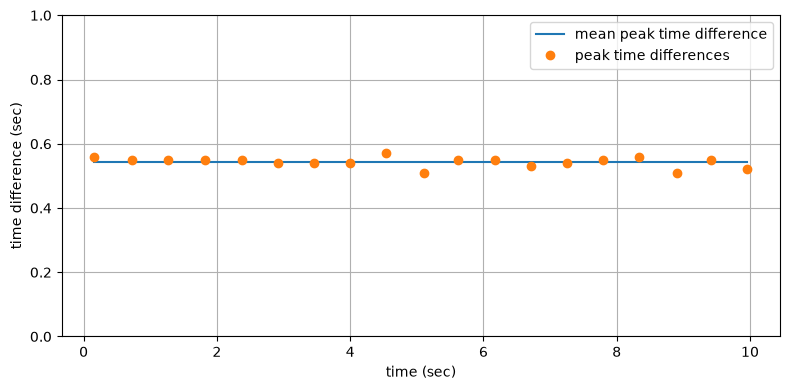

In [259]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4), tight_layout=True)
ax.plot(t_peaks[:-1], T * np.ones_like(t_peaks[:-1]), label='mean peak time difference')
ax.plot(t_peaks[:-1], t_diff, '.', markersize=12, label='peak time differences')
ax.set_ylim(0., 1.)
ax.set_xlabel('time (sec)')
ax.set_ylabel('time difference (sec)')
ax.grid()
ax.legend()
plt.show()

In [260]:
delta_T = max(abs(t_diff - T * np.ones_like(t_peaks[:-1])))
print(delta_T)

0.033157894736842386


Calculate the estimate of the moment of inertia as well as the J uncertainty.

In [261]:
J_y = m * (g * r * T**2 / (4 * np.pi**2) - r**2)
print(J_y)

delta_J_y = (
        abs(m * (g * T**2 / (4 * np.pi**2) - 2*r)) * delta_r
        + abs(g * r * T**2 / (4 * np.pi**2) - r**2) * delta_m
        + abs(m * g * r * T / (2 * np.pi**2)) * delta_T
    )
print(delta_J_y)

3.1880515698173055e-05
2.4139454857533214e-05


# 5. Estimate the moment of inertia about the $z_B$-axis

In [262]:
# Load data
raw_data_drone, raw_data_mocap, raw_data_bodies = load_hardware_data('z_data.json')

# Resample data
data_drone = resample_data_drone(
    raw_data_drone,
    t_min_offset=0.,    # <-- FIXME
    t_max_offset=0.,    # <-- FIXME
)

# Parse data
t = data_drone['time']
w_x = np.deg2rad(data_drone['gyro.x'])
w_y = np.deg2rad(data_drone['gyro.y'])
w_z = np.deg2rad(data_drone['gyro.z'])

Add cells here to repeat the same process as above...

In [263]:
r = 0.03
delta_r = 0.001

# Find the index of each peak (increase "prominence" if you get bad results)
peaks = find_peaks(w_z, prominence=1)
i_peaks = peaks[0]

# Find the time at each peak
t_peaks = t[i_peaks]

# Find w_x at each peak (for visualization)
w_z_peaks = w_z[i_peaks]

t_diff = t_peaks[1:] - t_peaks[:-1]

# Find the mean difference as an estimate of the oscillation period
T = np.mean(t_diff)

# Print the estimate
print(f'T = {T:.4f} sec')

T = 0.5650 sec


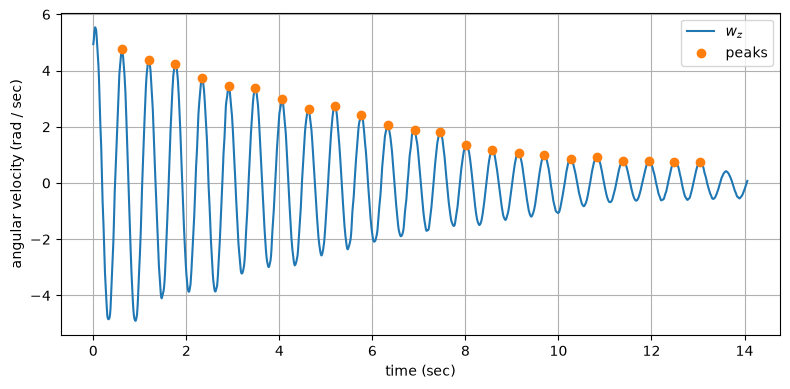

In [264]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4), tight_layout=True)
ax.plot(t, w_z, label='$w_z$')
ax.plot(t_peaks, w_z_peaks, '.', markersize=12, label='peaks')
ax.set_xlabel('time (sec)')
ax.set_ylabel('angular velocity (rad / sec)')
ax.legend()
ax.grid()
plt.show()

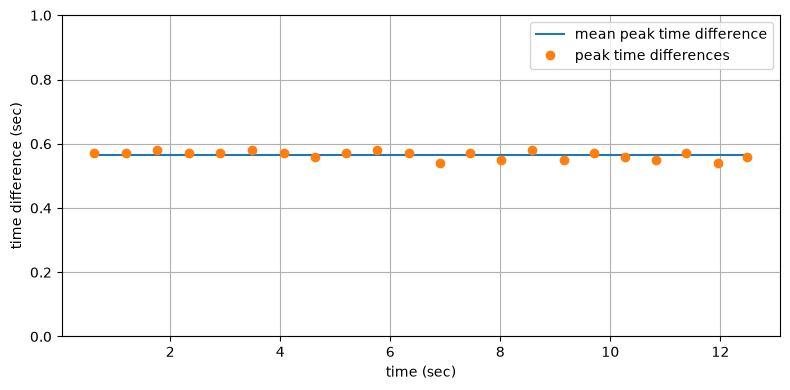

In [265]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4), tight_layout=True)
ax.plot(t_peaks[:-1], T * np.ones_like(t_peaks[:-1]), label='mean peak time difference')
ax.plot(t_peaks[:-1], t_diff, '.', markersize=12, label='peak time differences')
ax.set_ylim(0., 1.)
ax.set_xlabel('time (sec)')
ax.set_ylabel('time difference (sec)')
ax.grid()
ax.legend()
plt.show()

In [266]:
delta_T = max(abs(t_diff - T * np.ones_like(t_peaks[:-1])))
print(delta_T)

0.02499999999999991


In [267]:
J_z = m * (g * r * T**2 / (4 * np.pi**2) - r**2)
print(J_z)

delta_J_z = (
        abs(m * (g * T**2 / (4 * np.pi**2) - 2*r)) * delta_r
        + abs(g * r * T**2 / (4 * np.pi**2) - r**2) * delta_m
        + abs(m * g * r * T / (2 * np.pi**2)) * delta_T
    )
print(delta_J_z)

5.915518055073632e-05
1.067153130357785e-05


# 6. Summarize and discuss the results

### Summary of results

In [268]:
print(f'm = {m:.4f} +/- {delta_m:.4f} kg')
print(f'J_x = {J_x:.2e} +/- {delta_J_x:.2e} kg m^2')
print(f'J_y = {J_y:.2e} +/- {delta_J_y:.2e} kg m^2')
print(f'J_z = {J_z:.2e} +/- {delta_J_z:.2e} kg m^2')

m = 0.0400 +/- 0.0010 kg
J_x = 2.92e-05 +/- 1.61e-05 kg m^2
J_y = 3.19e-05 +/- 2.41e-05 kg m^2
J_z = 5.92e-05 +/- 1.07e-05 kg m^2


### Analysis of uncertainty

**Modify the text in this cell** to answer the following questions:
* Which computed quantities ($J_x$, $J_y$, $J_z$) are the most uncertain?

From the values printed above, J_y appears to be the most uncertain.

* Which measured quantities ($m$, $r$, $T$) contribute the most to uncertainty in the computed quantities?
* What assumptions were made and to what extent were these assumptions violated?
* What sources of error might not be captured in your analysis of uncertainty?

### Ways to improve the results

First and foremost, the use of more precise equipment would improve uncertainty. Secondly, during the pendulum test, the drone was not fully held to a single axis of rotation, especially in the z-axis test. Such movement

### Reflection

Review the reflection you put in your Lab 2 notebook. **Modify the text in this cell** to answer the following three questions with at least one sentence each:
* What was your biggest struggle this week? Was it the same or different from last week?
* What was the most important thing you learned this week?
* How does what you learned this week relate to what you learned last week?